# Лабораторная работа № 6. Хранение, очистка и структурирование данных
**Студент:** Мурашова Арина | **Вариант:** 2 («Книги и авторы»)

В блокноте выполняется воспроизводимая пересборка трёхслойного хранилища `raw → clean → mart` из сырых данных (`books.toscrape.com` HTML + `Open Library REST API`), сравнение форматов хранения (CSV, JSON Lines, Parquet), проверка контракта `pydantic`, тестирование идемпотентности и ограничений SQLite, расчёт 8 метрик качества («светофор») и визуализация аналитических витрин.


In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.').resolve()
if not (ROOT / 'raw').exists() and (ROOT / 'Lab6' / 'raw').exists():
    ROOT = ROOT / 'Lab6'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.clean import load_raw_sources, run_cleaning_pipeline
from src.contract import validate_clean_tables, run_contract_probes
from db.load import run_idempotency_demo, run_constraint_tests
from src.quality import evaluate_quality, enforce_quality_gate, QualityGateError
from src.rebuild import run_format_benchmark, build_mart

raw_df = load_raw_sources(ROOT / 'raw')
print(f'Загружено сырых записей: {len(raw_df)}')
print(raw_df['_source'].value_counts().to_string())


Загружено сырых записей: 396
_source
openlibrary_api        204
books_toscrape_html    192


## 1. Шестишаговая очистка и протокол изменений


In [2]:
books_df, authors_df, rejects_df, protocol_df = run_cleaning_pipeline(raw_df)
display(protocol_df)


,шаг,строк до,строк после,изменено/удалено,примечание
0,1. Нормализация текста,396,396,7,"NFKC, удаление \xa0 и zero-width, нормализован..."
1,2. Бизнес-ключ и URL,396,396,4,Ключи upc:/olw: и ol_author:; очищено URL с па...
2,3. Типизация,396,396,1,"Decimal для цен (не разобрано: 1), Int64 для ц..."
3,4. Обработка пропусков,396,388,8,Отбраковано в rejects: 8; необязательные поля ...
4,5. Дедупликация,388,377,11,Удалено полных и «почти-дублей» по book_key: 1...
5,6. Бизнес-правила (6 правил),377,370,7,Отбраковано по бизнес-правилам: 7


## 2. Сравнение форматов хранения (CSV, JSON Lines, Parquet)


In [3]:
bench_df = run_format_benchmark(books_df, ROOT / 'clean')
display(bench_df)


,формат,строк,размер_КБ,чтение_всего_мс,чтение_2_столбцов_мс,тип_collected_at,пример_catalog_code
0,CSV,37000,3255.73,41.39,25.65,object,1000
1,JSON Lines,37000,6651.76,245.19,251.54,"datetime64[ns, UTC]",1000
2,Parquet (snappy),37000,50.56,354.49,13.44,"datetime64[ns, UTC]",01000


## 3. Контракт данных (Pydantic v2) и тестирование на заведомо битых записях


In [4]:
valid_authors, valid_books, contract_rejects = validate_clean_tables(books_df, authors_df)
print(f'Прошли контракт: авторов = {len(valid_authors)}, книг = {len(valid_books)}, отбраковано = {len(rejects_df)}')
probes_df = run_contract_probes(valid_books[0])
display(probes_df)


Прошли контракт: авторов = 60, книг = 370, отбраковано = 15


,проверка,результат,сообщение об ошибке
0,1. Отрицательная цена (price = -15.00),отклонена,price: Input should be greater than 0
1,2. Рейтинг вне диапазона 1..5 (rating = 7),отклонена,rating: Input should be less than or equal to 5
2,3. Пустой заголовок после обрезки (title = ' '),отклонена,"title: Value error, Название книги не может со..."
3,4. Наивная дата без таймзоны UTC,отклонена,"collected_at: Value error, Метка времени colle..."
4,5. URL без схемы http(s)://,отклонена,"source_url: Value error, URL должен начинаться..."
5,6. Несогласованность: in_stock=True при stock=0,отклонена,"model: Value error, Несогласованность: книга о..."


## 4. База данных SQLite: идемпотентный UPSERT (3 прогона), история изменений и ограничения


In [5]:
runs_df, history_df = run_idempotency_demo(ROOT / 'db/warehouse.db', ROOT / 'db/schema.sql', valid_authors, valid_books, rejects_df)
display(runs_df)
display(history_df)


,сценарий,передано_книг,всего_книг_в_БД,обновлено_книг,всего_авторов_в_БД,обновлено_авторов
0,Прогон 1: первичная загрузка,370,370,370,60,60
1,Прогон 2: повтор с теми же данными,370,370,0,60,0
2,Прогон 3: изменены 2 записи,370,370,2,60,0


,book_key,title,observed_at,price,stock,rating
0,upc:6957f44c3847a760,Soumission,2026-11-19T10:00:00+00:00,50.10,20,1
1,upc:6957f44c3847a760,Soumission,2026-11-19T11:00:00+00:00,50.10,20,1
2,upc:6957f44c3847a760,Soumission,2026-11-19T12:00:00+00:00,50.10,24,1
3,upc:90fa61229261140a,Tipping the Velvet,2026-11-19T10:00:00+00:00,53.74,20,1
4,upc:90fa61229261140a,Tipping the Velvet,2026-11-19T11:00:00+00:00,53.74,20,1
5,upc:90fa61229261140a,Tipping the Velvet,2026-11-19T12:00:00+00:00,58.74,20,1


In [6]:
constraints_df = run_constraint_tests(ROOT / 'db/warehouse.db')
display(constraints_df)


,проверка ограничения БД,результат,сообщение СУБД
0,1. Отрицательная цена (CHECK price > 0),отклонено СУБД,CHECK constraint failed: price IS NULL OR CAST...
1,2. Рейтинг вне диапазона 1..5 (CHECK rating BE...,отклонено СУБД,CHECK constraint failed: rating IS NULL OR rat...
2,3. Дублирующийся первичный ключ (PRIMARY KEY b...,отклонено СУБД,UNIQUE constraint failed: books.book_key
3,4. Несуществующий автор (FOREIGN KEY author_key),отклонено СУБД,FOREIGN KEY constraint failed


## 5. Метрики качества и «светофор»


In [7]:
ref_time = pd.to_datetime(books_df['collected_at'], utc=True).max().to_pydatetime()
quality_df, verdict = evaluate_quality(raw_df, books_df, rejects_df, reference_now=ref_time)
print('Итоговый вердикт:', verdict)
enforce_quality_gate(quality_df)
display(quality_df[['метрика', 'значение', 'пороги (зелёный / жёлтый)', 'статус']])


Итоговый вердикт: ПРИГОДЕН (ЗЕЛЁНЫЙ)


,метрика,значение,пороги (зелёный / жёлтый),статус
0,"1. Полнота обязательных полей, %",100.00,>= 100.0 / >= 99.0,зелёный
1,"2. Полнота необязательных полей, %",66.67,>= 55.0 / >= 35.0,зелёный
2,"3. Уникальность бизнес-ключа, %",100.00,>= 100.0 / >= 99.0,зелёный
3,"4. Валидность (доля от сырых записей), %",93.43,>= 90.0 / >= 75.0,зелёный
4,"5. Доля отбраковки, %",3.79,<= 5.0 / <= 15.0,зелёный
5,"6. Согласованность бизнес-правил, %",100.00,>= 100.0 / >= 98.0,зелёный
6,"7. Актуальность данных (возраст), ч",0.00,<= 48.0 / <= 168.0,зелёный
7,"8. Отклонение объёма от прошлого прогона, %",0.00,<= 10.0 / <= 25.0,зелёный


## 6. Аналитические витрины слоя `mart/`, партиционирование и графики


Партиции снапшотов: ['dt=2026-11-18'] (записей в партии: 370)


C:\Users\muras\OneDrive\Desktop\DATA MINING\Lab6\src\rebuild.py:96: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  в_наличии=("in_stock", lambda s: int(s.fillna(False).sum())),


,category,книг,средняя_цена,медианная_цена,средний_рейтинг,в_наличии
0,Fiction,44,38.87,42.15,3.7,9
1,Classics,40,39.69,39.86,3.82,8
2,Science Fiction,38,36.73,41.89,3.79,9
3,Fantasy,29,38.34,35.70,4.0,8
4,Thriller,21,27.35,24.59,3.57,8
5,Poetry,21,34.54,28.90,3.29,12
6,Mystery,20,37.98,43.61,3.8,9
7,History,15,33.74,30.43,3.13,9
8,Science,15,34.76,31.42,3.8,8
9,Historical Fiction,15,40.76,46.05,3.27,9


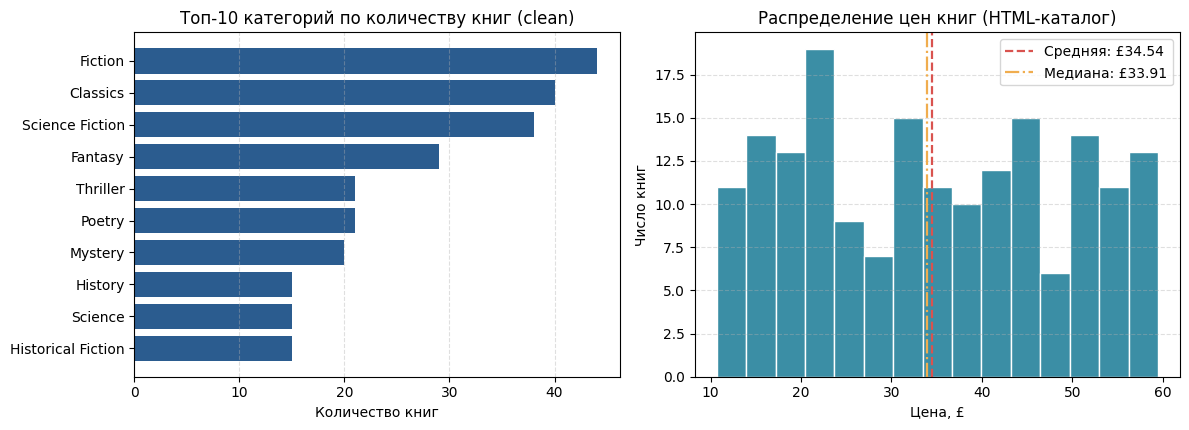

In [8]:
mart_info = build_mart(books_df, authors_df, ROOT / 'mart')
print(f"Партиции снапшотов: {mart_info['partitions']} (записей в партии: {mart_info['sample_partition_rows']})")
display(mart_info['cat_summary'].head(10))

work = books_df.copy()
work['price_num'] = work['price'].map(lambda x: float(x) if x is not None else None)
cat_summary = mart_info['cat_summary']

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
top_cats = cat_summary.head(10).iloc[::-1]
ax1.barh(top_cats['category'], top_cats['книг'], color='#2b5c8f')
ax1.set_title('Топ-10 категорий по количеству книг (clean)')
ax1.set_xlabel('Количество книг')
ax1.grid(axis='x', linestyle='--', alpha=0.4)

priced_vals = work['price_num'].dropna()
ax2.hist(priced_vals, bins=15, color='#3b8ea5', edgecolor='white')
ax2.axvline(priced_vals.mean(), color='#d9534f', linestyle='--', linewidth=1.6, label=f"Средняя: £{priced_vals.mean():.2f}")
ax2.axvline(priced_vals.median(), color='#f0ad4e', linestyle='-.', linewidth=1.6, label=f"Медиана: £{priced_vals.median():.2f}")
ax2.set_title('Распределение цен книг (HTML-каталог)')
ax2.set_xlabel('Цена, £')
ax2.set_ylabel('Число книг')
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


,author_key,author_name,birth_year,work_count,книг_в_каталоге,средний_рейтинг,средний_год_публикации
1,ol_author:OL26321A,J.R.R. Tolkien,1892,340,5,4.4,1955.4
2,ol_author:OL22242A,Fyodor Dostoevsky,1821,680,5,4.2,1870.2
3,ol_author:OL118077A,George Orwell,1903,412,5,4.0,1940.4
4,ol_author:OL21594A,Jane Austen,1775,490,5,4.0,1814.0
5,ol_author:OL2162284A,Stephen King,1947,395,5,4.0,1987.8
6,ol_author:OL24638A,Charles Dickens,1812,920,5,4.0,1850.2
7,ol_author:OL25712A,Isaac Asimov,1920,540,5,4.0,1955.6
8,ol_author:OL27695A,Agatha Christie,1890,530,5,4.0,1934.4
9,ol_author:OL9388A,William Shakespeare,1564,1850,5,4.0,1603.8
10,ol_author:OL23919A,J.K. Rowling,1965,145,4,4.75,1998.5


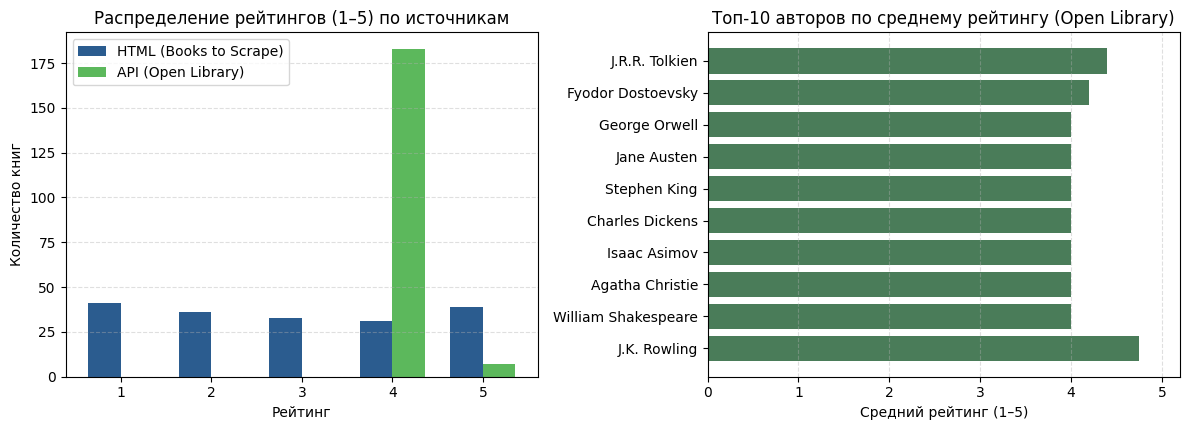

In [9]:
author_stats = mart_info['author_stats']
display(author_stats[author_stats['author_key'] != 'unknown_toscrape'].head(10))

fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(12, 4.4))
rating_pivot = (
    work.dropna(subset=['rating'])
    .groupby(['rating', 'source'])['book_key']
    .count()
    .unstack(fill_value=0)
)
rating_pivot.plot(kind='bar', ax=ax3, color=['#2b5c8f', '#5cb85c'], width=0.72)
ax3.set_title('Распределение рейтингов (1–5) по источникам')
ax3.set_xlabel('Рейтинг')
ax3.set_ylabel('Количество книг')
ax3.tick_params(axis='x', rotation=0)
ax3.legend(['HTML (Books to Scrape)', 'API (Open Library)'])
ax3.grid(axis='y', linestyle='--', alpha=0.4)

top_auth = author_stats[author_stats['author_key'] != 'unknown_toscrape'].head(10).iloc[::-1]
ax4.barh(top_auth['author_name'], top_auth['средний_рейтинг'], color='#4a7c59')
ax4.set_xlim(0, 5.2)
ax4.set_title('Топ-10 авторов по среднему рейтингу (Open Library)')
ax4.set_xlabel('Средний рейтинг (1–5)')
ax4.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
